# Preparação, Limpeza e Transformação de Dados

**Aluna:** Layse Steffany Pereira de Souza · UDF · Sistemas de Informação · Ciência de Dados e Aprendizado de Máquina (2026/2)

**Aula:** 18/11 (e Avaliação Final de 09/12) · Unidade V – Tratamento de Dados
**Atividade:** tratar dados ausentes, inconsistentes e duplicados e preparar a base para análise.
**Entregável:** dataset tratado (`dados/tratados/arquivos_pe_tratado.csv`) +
notebook/documentação das transformações (`documentacao_transformacoes.md`).

As regras ficam em `src/preparacao.py` para que **todos** os notebooks usem exatamente a mesma base.
Aqui cada problema é mostrado **antes**, a transformação é aplicada e o resultado é verificado **depois**.

In [1]:
import sys
from pathlib import Path

# Permite importar o pacote src/ a partir da pasta do notebook.
# No Google Colab, antes de rodar:
#   !git clone https://github.com/LaySteff/ciencia_dados_aprendizado_maquina.git
#   %cd ciencia_dados_aprendizado_maquina/unidade5_tratamento_de_dados
RAIZ = Path.cwd().resolve().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 30)
FIGURAS = RAIZ / "figuras"
FIGURAS.mkdir(exist_ok=True)

if config.usando_dados_sinteticos():
    print("AVISO: usando a base SINTÉTICA de demonstração. "
          "Os números abaixo são ilustrativos; refaça com a amostra real do EMBER.")
else:
    print("Usando a amostra real do EMBER.")

AVISO: usando a base SINTÉTICA de demonstração. Os números abaixo são ilustrativos; refaça com a amostra real do EMBER.


In [2]:
from src.preparacao import carregar_bruto, preparar, salvar, MAPA_BOOLEANO

bruto = carregar_bruto()
print("Base bruta:", bruto.shape)

Base bruta: (6150, 18)


## 1. Diagnóstico (antes)

In [3]:
num = bruto[config.COLUNAS_NUMERICAS].apply(pd.to_numeric, errors="coerce")
diagnostico = pd.Series({
    "linhas duplicadas": bruto.duplicated().sum(),
    "sha256 fora do padrão": (bruto["sha256"] != bruto["sha256"].str.strip().str.lower()).sum(),
    "amostras sem rótulo (label=-1)": (bruto["label"] == -1).sum(),
    "datas em MM/AAAA": bruto["mes_aparicao"].str.contains("/").sum(),
    "booleanos em texto (sim/não/S/N...)": sum((~bruto[c].astype(str).isin(["0", "1", "0.0", "1.0", "nan"])).sum()
                                               for c in config.COLUNAS_BOOLEANAS),
    "valores ausentes": bruto.isna().sum().sum(),
    "entropia > 8": (num.filter(like="entropia") > 8).sum().sum(),
    "tamanho <= 0": (num["tamanho_bytes"] <= 0).sum(),
}, name="ocorrências")
diagnostico.to_frame()

,ocorrências
linhas duplicadas,150
sha256 fora do padrão,304
amostras sem rótulo (label=-1),310
datas em MM/AAAA,489
booleanos em texto (sim/não/S/N...),1357
valores ausentes,642
entropia > 8,32
tamanho <= 0,18


In [4]:
print("Exemplos de valores em possui_assinatura:", bruto["possui_assinatura"].astype(str).value_counts().head(8).to_dict())
print("Mapeamento aplicado:", MAPA_BOOLEANO)

Exemplos de valores em possui_assinatura: {'0': 3267, '1': 2268, 'false': 99, 'não': 91, 'nao': 89, 'N': 83, 'Sim': 80, 'true': 60}
Mapeamento aplicado: {'1': 1, '1.0': 1, 'sim': 1, 's': 1, 'true': 1, 'verdadeiro': 1, '0': 0, '0.0': 0, 'não': 0, 'nao': 0, 'n': 0, 'false': 0, 'falso': 0}


## 2. Aplicação das transformações

In [5]:
tratado, relatorio = preparar(bruto)
pd.DataFrame(relatorio["etapas"]).set_index("etapa").fillna("")

,descricao,datas_convertidas,linhas_apos,duplicatas_exatas,duplicatas_sha256,removidas,valores_convertidos,valores_invalidados,valores_imputados,linhas_ajustadas
etapa,,,,,,,,,,
1. Padronização de texto,sha256 sem espaços e em minúsculas; mes_aparic...,489.0,6150,,,,,,,
2. Remoção de duplicatas,linhas idênticas e arquivos repetidos (mesmo s...,,6000,150.0,0.0,,,,,
3. Remoção de amostras sem rótulo,label = -1 (não rotulado) ou ausente,,5700,,,300.0,,,,
4. Padronização de booleanos,sim/não/S/N/true/false convertidos para 1/0,,5700,,,,1133.0,,,
5. Valores inválidos,"entropia fora de [0, 8], tamanho <= 0 e contag...",,5700,,,,,47.0,,
6. Imputação de ausentes,"mediana para numéricos, moda para booleanos e ...",,5700,,,,,,650.0,
7. Consistência entre colunas,entropia_max_secao ajustada quando menor que a...,,5700,,,,,,,50.0
8. Transformação logarítmica,log10_tamanho criado a partir de tamanho_bytes,,5700,,,,,,,
9. Outliers,identificados pelo critério IQR e mantidos,,5700,,,,,,,


## 3. Verificação (depois)

In [6]:
checagens = {
    "sem valores ausentes": tratado[config.FEATURES + ["label"]].isna().sum().sum() == 0,
    "sem duplicatas de sha256": not tratado["sha256"].duplicated().any(),
    "rótulo só 0/1": set(tratado["label"].unique()) <= {0, 1},
    "booleanos só 0/1": all(set(tratado[c].unique()) <= {0, 1} for c in config.COLUNAS_BOOLEANAS),
    "entropias em [0, 8]": tratado.filter(like="entropia").apply(lambda s: s.between(0, 8).all()).all(),
    "tamanho > 0": (tratado["tamanho_bytes"] > 0).all(),
    "datas no formato AAAA-MM": tratado["mes_aparicao"].str.fullmatch(r"\d{4}-\d{2}").all(),
    "entropia máx >= média": (tratado["entropia_max_secao"] >= tratado["entropia_media_secao"]).all(),
}
assert all(checagens.values()), checagens
pd.Series(checagens, name="ok").to_frame()

,ok
sem valores ausentes,True
sem duplicatas de sha256,True
rótulo só 0/1,True
booleanos só 0/1,True
"entropias em [0, 8]",True
tamanho > 0,True
datas no formato AAAA-MM,True
entropia máx >= média,True


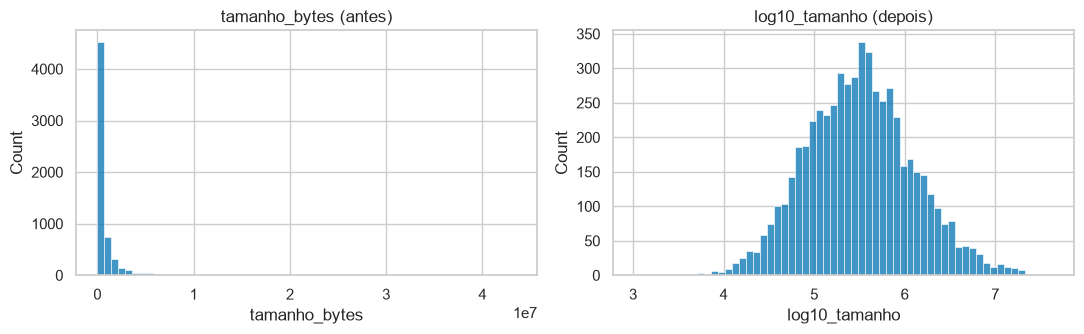

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(num["tamanho_bytes"].clip(lower=1), ax=axes[0], bins=60); axes[0].set_title("tamanho_bytes (antes)")
sns.histplot(tratado["log10_tamanho"], ax=axes[1], bins=60); axes[1].set_title("log10_tamanho (depois)")
plt.tight_layout(); plt.show()

## 4. Salvando a base tratada

In [8]:
salvar(tratado, relatorio)
print(f"{relatorio['linhas_iniciais']} linhas → {relatorio['linhas_finais']} linhas")
print("Classes:", relatorio["distribuicao_classes"])
print("Arquivos:", config.ARQ_TRATADO.relative_to(RAIZ), "|", config.ARQ_RELATORIO.relative_to(RAIZ))
tratado.head()

6150 linhas → 5700 linhas
Classes: {'0': 3056, '1': 2644}
Arquivos: dados\tratados\arquivos_pe_tratado.csv | dados\tratados\relatorio_transformacoes.json


,sha256,mes_aparicao,tamanho_bytes,num_secoes,entropia_media_secao,entropia_max_secao,num_importacoes,num_exportacoes,num_strings,entropia_strings,num_urls,num_paths,num_registro,possui_assinatura,possui_debug,possui_recursos,secao_exec_gravavel,label,log10_tamanho
0,77d83921b8077273000000000000000000000000000000...,2018-11,4197.0,4.0,4.4947,5.5865,118.0,0.0,1293.0,5.5455,4.0,4.0,0.0,0,0,1,0,0,3.622939
1,7cc9c3a35ba409b5000000000000000000000000000000...,2018-05,1157473.0,5.0,4.9759,6.2030,84.0,14.0,730.0,5.4929,1.0,1.0,3.0,0,0,1,0,1,6.063511
2,1c83bd40f2d026b7000000000000000000000000000000...,2018-12,252668.0,5.0,5.9036,6.3224,34.0,6.0,1171.0,5.4819,2.0,1.0,0.0,1,0,1,0,0,5.402550
3,6009e80f65c8db78000000000000000000000000000000...,2018-02,67035.0,6.0,6.3451,7.2603,66.0,0.0,1374.0,6.0296,3.0,3.0,6.0,0,0,0,0,1,4.826302
4,074b085fa5aaf64b000000000000000000000000000000...,2018-01,126676.0,10.0,5.9337,7.5723,134.0,9.0,5787.0,4.9200,3.0,6.0,0.0,1,0,0,0,0,5.102694
